# 0d — Analyse exploratoire · Segment : Comptes joints

**Objectif** : dérouler le chapitre 3 du cours — associations et redondances entre variables — sur la
base préparée du segment *comptes joints* (sortie du notebook `0c`).

| § | Thème | Outils |
|---|-------|--------|
| 3.1 | Quanti / quanti | Pearson, Spearman, Kendall |
| 3.2 | Quali / quali | Chi², V de Cramer |
| 3.3 | Quanti / quali | ANOVA, eta², Kruskal-Wallis |
| 3.4 | Multicolinéarité | matrice de corrélation, VIF, ACP exploratoire |
| 3.5 | Relations non monotones | taux de défaut par classe |
| 3.6 | Limites pour la sélection | statut provisoire de chaque variable |

> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/exploration.py`
> et `utils/binning.py`. Seuls les paramètres et les décisions figurent ici.

## 0. Imports et configuration

In [1]:
import sys
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import polars as pl
import matplotlib.pyplot as plt

from utils.binning import iv_ranking
from utils.exploration import (
    missing_report, constant_report, chi2_association,
    correlation_matrix, paires_redondantes, vif_report, preselection_variables, exporter_excel,
    liaison_quanti_cible, cramers_v_matrix, anova_report, eta2_matrix, paires_fortes,
    completer_mediane, acp_exploratoire, monotonie_report,
    plot_matrice, plot_acp, plot_tdr_classes, plot_iv_correlees,
)
from utils.synthese import afficher, lecture_acp, constat_preselection, synthese_exploration

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)

polars.config.Config

In [2]:
BASE       = ROOT / "data/segments/joint/base_joint_prep.parquet"
EXPORT     = ROOT / "outputs/exploration/exploration_joint.xlsx"
CANDIDATES = ROOT / "outputs/exploration/variables_candidates_joint.json"   # entrée du ch. 4

TARGET   = "ddefaut_ndb"   # variable cible (0/1)
ID_COL   = "gdt"           # identifiant
DATE_COL = "datdelhis"     # date d'observation

# Colonnes techniques, hors du champ des variables explicatives
EXCLUDE  = [ID_COL, TARGET, DATE_COL, "segment", "SelectionProb", "SamplingWeight",
            "type_PM_PP", "code_marche_v2", "echantillon"]

MAX_MODALITES     = 15     # au-delà, une variable numérique est traitée comme continue
MAX_MODALITES_V   = 50     # au-delà, une variable qualitative est écartée des V de Cramer
N_TOP             = 20     # nombre de variables affichées dans les matrices et l'ACP

SEUIL_CORR        = 0.8    # |Spearman| au-delà duquel deux variables sont jugées redondantes
SEUIL_CRAMER      = 0.8    # V de Cramer au-delà duquel deux variables sont jugées redondantes
SEUIL_VIF         = 5      # VIF au-delà duquel la multicolinéarité est jugée préoccupante
ALPHA             = 0.05

# Règles de statut provisoire (3.6) : mêmes valeurs que la présélection du notebook 0c
IV_MIN            = 0.02           # seuil de Siddiqi : en dessous, variable non prédictive
MISSING_MAX       = 0.95           # taux de manquants à partir duquel la variable est écartée
IV_RARE           = float("inf")   # toute variable quasi constante est écartée (comme en 0c)

## 1. Chargement

On lit la base préparée par le notebook `0c` : manquant = modalité `"missing"` pour les variables
qualitatives, `null` pour les quantitatives ; valeurs extrêmes winsorisées.

L'analyse porte sur l'**échantillon d'apprentissage** (découpage fait en `0c`) : la liste des variables candidates
transmise au chapitre 4 ne doit rien devoir à l'échantillon de test.

In [3]:
if not BASE.exists():
    raise FileNotFoundError(f"{BASE} introuvable : exécuter d'abord le notebook 0c.")

df = pl.read_parquet(BASE).filter(pl.col("echantillon") == "apprentissage")   # cours 1.5.4

EXCLUDE = [c for c in EXCLUDE if c in df.columns]

VARS           = [c for c, t in df.schema.items() if c not in EXCLUDE and not t.is_temporal()]
VARS_QUANTI    = [c for c in VARS if df.schema[c].is_numeric()]
VARS_QUALI     = [c for c in VARS if c not in VARS_QUANTI]
n_valeurs      = {c: df[c].n_unique() for c in VARS}
VARS_CONTINUES = [c for c in VARS_QUANTI if n_valeurs[c] > MAX_MODALITES]
# Variables traitées comme qualitatives : les qualitatives et les numériques à peu de valeurs
VARS_DISCRETES = [c for c in VARS if c not in VARS_CONTINUES and 1 < n_valeurs[c] <= MAX_MODALITES_V]

print(f"Base : {df.height} lignes | taux de défaut : {df[TARGET].mean():.2%}")
print(f"{len(VARS)} variables : {len(VARS_QUANTI)} quantitatives (dont {len(VARS_CONTINUES)} continues), "
      f"{len(VARS_QUALI)} qualitatives")
print(f"{len(VARS_DISCRETES)} variables traitées comme qualitatives en 3.2")

Base : 47156 lignes | taux de défaut : 0.48%
62 variables : 56 quantitatives (dont 41 continues), 6 qualitatives
21 variables traitées comme qualitatives en 3.2


## 3.0 Introduction

L'analyse exploratoire répond à deux questions distinctes :

1. **Liaison avec la cible** : quelles variables sont associées au défaut ?
2. **Redondance** : quelles variables portent la même information ? Deux variables très liées
   entre elles ne doivent pas entrer ensemble dans la régression logistique (coefficients instables,
   signes incohérents).

Le test dépend de la nature des deux variables croisées, d'où le découpage 3.1 / 3.2 / 3.3. La cible
étant binaire, elle peut se lire comme quantitative (0/1) ou comme qualitative (sain / défaut).

**Repère : l'Information Value.** Pour choisir les variables affichées dans les matrices, et pour
confronter les mesures de ce chapitre à un pouvoir discriminant qui ne suppose aucune forme de
relation, on calcule dès maintenant l'IV de chaque variable sur un découpage fin (détaillé au ch. 4).

In [4]:
iv = iv_ranking(df, VARS, TARGET, max_modalites=MAX_MODALITES)

TOP_QUANTI = iv.filter(pl.col("variable").is_in(VARS_CONTINUES))["variable"].head(N_TOP).to_list()
TOP_QUALI  = iv.filter(pl.col("variable").is_in(VARS_DISCRETES))["variable"].head(N_TOP).to_list()

iv.head(N_TOP)

variable,iv,pouvoir,n_classes,min_n_classe
str,f64,str,i64,i64
"""MINSOLDE_PAR""",1.884791,"""suspect""",10,4703
"""CRTAD_IND_0038""",1.614595,"""suspect""",10,4658
"""solde_crediteur""",1.56405,"""suspect""",10,4715
"""CRTAD_AG_NBJDE_BA""",1.481339,"""suspect""",7,2950
"""CRTAD_AG_NBJDE_BB""",1.37795,"""suspect""",5,4087
"""CRTAD_IND_0015""",1.262532,"""suspect""",4,4523
"""ENCOURS_PAR""",1.165671,"""suspect""",9,3905
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…",1.093659,"""suspect""",3,166
"""CRTAE_AG_SLDEPA""",1.022851,"""suspect""",9,2457


## 3.1 Quanti / quanti : Pearson, Spearman, Kendall

| Coefficient | Mesure | Sensibilité |
|-------------|--------|-------------|
| **Pearson** | liaison *linéaire* | sensible aux valeurs extrêmes |
| **Spearman** | liaison *monotone* (corrélation des rangs) | robuste aux extrêmes |
| **Kendall** | liaison monotone (paires concordantes / discordantes) | robuste, mieux adapté aux ex æquo |

### Liaison avec la cible

Avec une cible 0/1, le Pearson est le coefficient point-bisérial. Les coefficients restent faibles en
valeur absolue : c'est attendu pour un événement rare, et cela ne préjuge pas du pouvoir discriminant.

In [5]:
liaison = liaison_quanti_cible(df, VARS_QUANTI, TARGET)

n_sig = liaison.filter(pl.col("pvalue_spearman") < ALPHA).height
print(f"{n_sig} variables quantitatives sur {len(VARS_QUANTI)} significativement liées à la cible (Spearman, p < {ALPHA})")

liaison.head(N_TOP)

46 variables quantitatives sur 56 significativement liées à la cible (Spearman, p < 0.05)


variable,n,pearson,spearman,kendall,pvalue_spearman
str,i64,f64,f64,f64,f64
"""RATIO_LITIGES_vs_AVOIRS""",37057,0.047776,0.176491,0.176477,5.5606e-257
"""ARR_GDT""",47156,0.122502,0.123764,0.122849,2.6180e-160
"""CRTAD_IND_0015""",47156,0.102648,0.085896,0.079853,6.3499e-78
"""CRTAD_AG_NBJDE_BB""",47156,0.102946,0.083526,0.075883,9.0323e-74
"""MINSOLDE_PAR""",47156,-0.026834,-0.081082,-0.066235,1.3043e-69
"""CRTAD_IND_0038""",47156,-0.029143,-0.0792,-0.064702,1.7146e-66
"""CRTAD_AG_NBJDE_BA""",47156,0.099746,0.07843,0.068463,3.0909e-65
"""NBJ_ARR_SS_max_Mm1_Mm3""",46986,0.075403,0.076716,0.076696,2.8636e-62
"""solde_crediteur""",47156,-0.027412,-0.076699,-0.062722,1.8459e-62


### Liaison entre variables explicatives

Matrice de Spearman sur les variables continues les plus discriminantes. Spearman est préféré à
Pearson : la discrétisation qui suit ne conserve que l'ordre des valeurs.

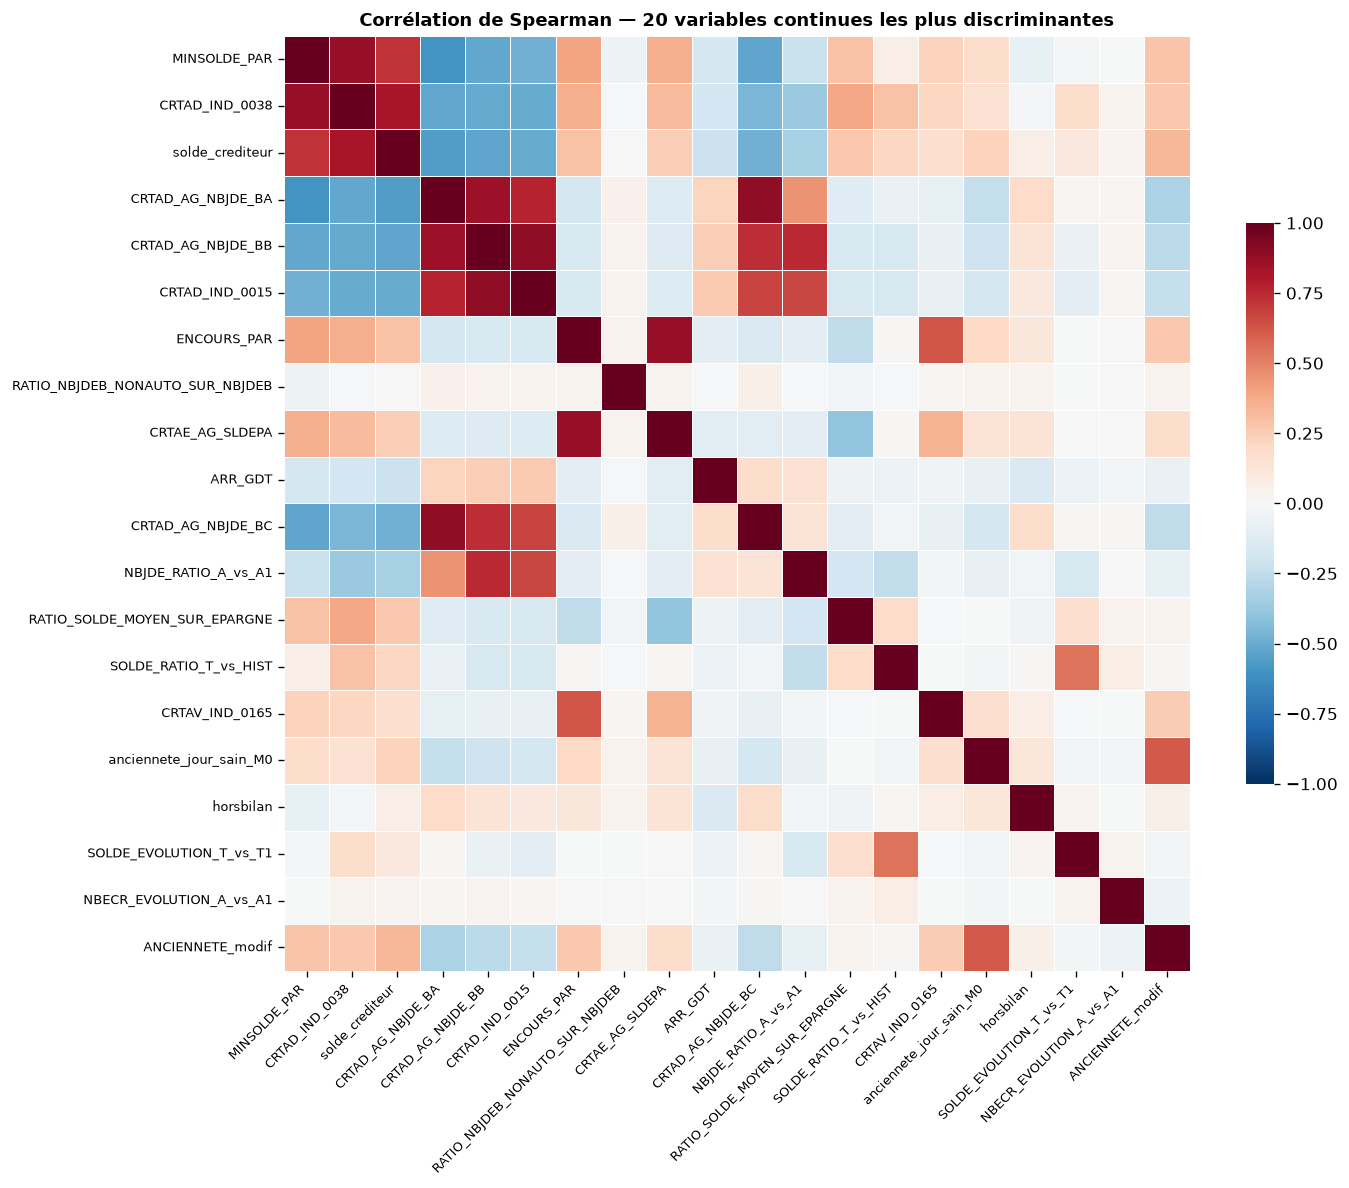

In [6]:
corr_spearman = correlation_matrix(df, TOP_QUANTI, method="spearman")

fig = plot_matrice(corr_spearman, titre=f"Corrélation de Spearman — {len(TOP_QUANTI)} variables continues les plus discriminantes")
plt.show()

**Pearson contre Spearman.** Un écart marqué entre les deux coefficients d'une même paire signale une
liaison monotone mais non linéaire, ou l'effet de valeurs extrêmes.

In [7]:
corr_pearson = correlation_matrix(df, TOP_QUANTI, method="pearson")

ecarts = (
    paires_fortes(corr_spearman, 0, "spearman")
    .join(paires_fortes(corr_pearson, 0, "pearson"), on=["var1", "var2"])
    .with_columns(ecart=pl.col("spearman").abs() - pl.col("pearson").abs())
    .sort(pl.col("ecart").abs(), descending=True)
)
ecarts.head(10)

var1,var2,spearman,pearson,ecart
str,str,f64,f64,f64
"""CRTAD_AG_NBJDE_BB""","""NBJDE_RATIO_A_vs_A1""",0.75753,0.262285,0.495245
"""CRTAD_IND_0015""","""NBJDE_RATIO_A_vs_A1""",0.666111,0.249189,0.416922
"""MINSOLDE_PAR""","""CRTAD_AG_NBJDE_BA""",-0.595575,-0.197192,0.398383
"""CRTAD_AG_NBJDE_BA""","""NBJDE_RATIO_A_vs_A1""",0.451327,0.069822,0.381505
"""solde_crediteur""","""CRTAD_AG_NBJDE_BA""",-0.559865,-0.183372,0.376493
"""solde_crediteur""","""CRTAD_AG_NBJDE_BB""",-0.531059,-0.173886,0.357173
"""MINSOLDE_PAR""","""CRTAD_AG_NBJDE_BB""",-0.519896,-0.176754,0.343142
"""MINSOLDE_PAR""","""CRTAD_AG_NBJDE_BC""",-0.528222,-0.189406,0.338816
"""CRTAD_IND_0038""","""CRTAD_AG_NBJDE_BA""",-0.523187,-0.187777,0.33541


### Paires redondantes

Recherche sur **toutes** les variables quantitatives des paires dont le Spearman dépasse le seuil en
valeur absolue.

In [8]:
paires_quanti = paires_redondantes(df, VARS_QUANTI, seuil=SEUIL_CORR)

print(f"{paires_quanti.height} paires avec |Spearman| >= {SEUIL_CORR}")
paires_quanti.head(30)

15 paires avec |Spearman| >= 0.8


var1,var2,spearman,n_commun
str,str,f64,i64
"""nb_credit_immo""","""nb_credit_immo__crelog""",0.894301,47156
"""CRTAD_IND_0015""","""CRTAD_AG_NBJDE_BB""",0.888417,47156
"""CRTAD_AG_NBJDE_BA""","""CRTAD_AG_NBJDE_BC""",0.883821,47156
"""CRTAD_IND_0042""","""CRTAD_AG_NBECR_B""",0.876728,47156
"""horsbilan""","""engagement_DAV""",0.875266,47156
"""engagement""","""bilan""",0.874846,47156
"""NBECR_PAR""","""NBECR_EVOLUTION_A_vs_A1""",-0.874099,45791
"""ENCOURS_PAR""","""CRTAE_AG_SLDEPA""",0.870029,47156
"""CRTAD_IND_0038""","""MINSOLDE_PAR""",0.86841,47156


## 3.2 Quali / quali : Chi², V de Cramer

Le test du **Chi²** dit si deux variables qualitatives sont indépendantes, mais sa statistique croît
avec l'effectif : sur une grande base, tout devient significatif. Le **V de Cramer** la ramène entre
0 (indépendance) et 1 (liaison parfaite), ce qui permet de comparer les variables entre elles.

Sont traitées ici les variables qualitatives et les variables numériques à peu de valeurs distinctes.

### Liaison avec la cible

In [9]:
chi2_cible = (
    pl.DataFrame([chi2_association(df, c, TARGET) for c in VARS_DISCRETES],
                 schema={"variable": pl.String, "chi2": pl.Float64, "pvalue": pl.Float64,
                         "dof": pl.Int64, "cramers_v": pl.Float64})
    .sort("cramers_v", descending=True, nulls_last=True)
)

n_sig = chi2_cible.filter(pl.col("pvalue") < ALPHA).height
print(f"{n_sig} variables sur {len(VARS_DISCRETES)} non indépendantes de la cible (Chi², p < {ALPHA})")

chi2_cible.head(N_TOP)

13 variables sur 21 non indépendantes de la cible (Chi², p < 0.05)


variable,chi2,pvalue,dof,cramers_v
str,f64,f64,i64,f64
"""RATIO_LITIGES_vs_AVOIRS""",1537.372506,0.0,14,0.18056
"""CAUSE_SAIN_M0""",553.824967,1.0300e-119,3,0.108372
"""NBJ_ARR_SS_max_Mm1_Mm3""",279.427281,2.8168e-60,3,0.076978
"""NBJ_ARR_SS_max_Mm7_Mm9""",268.229425,5.6849e-59,2,0.07542
"""NBJ_ARR_SS_max_Mm10_Mm12""",252.612724,7.6992e-51,7,0.073191
"""NBJ_ARR_SS_max_Mm4_Mm6""",161.033859,1.0763e-35,2,0.058437
"""nb_DAV""",48.467499,8.0409e-8,8,0.03206
"""anciennete""",27.386704,0.000005,3,0.024099
"""nb_CB_diff""",22.496334,0.000013,2,0.021842


### Liaison entre variables explicatives

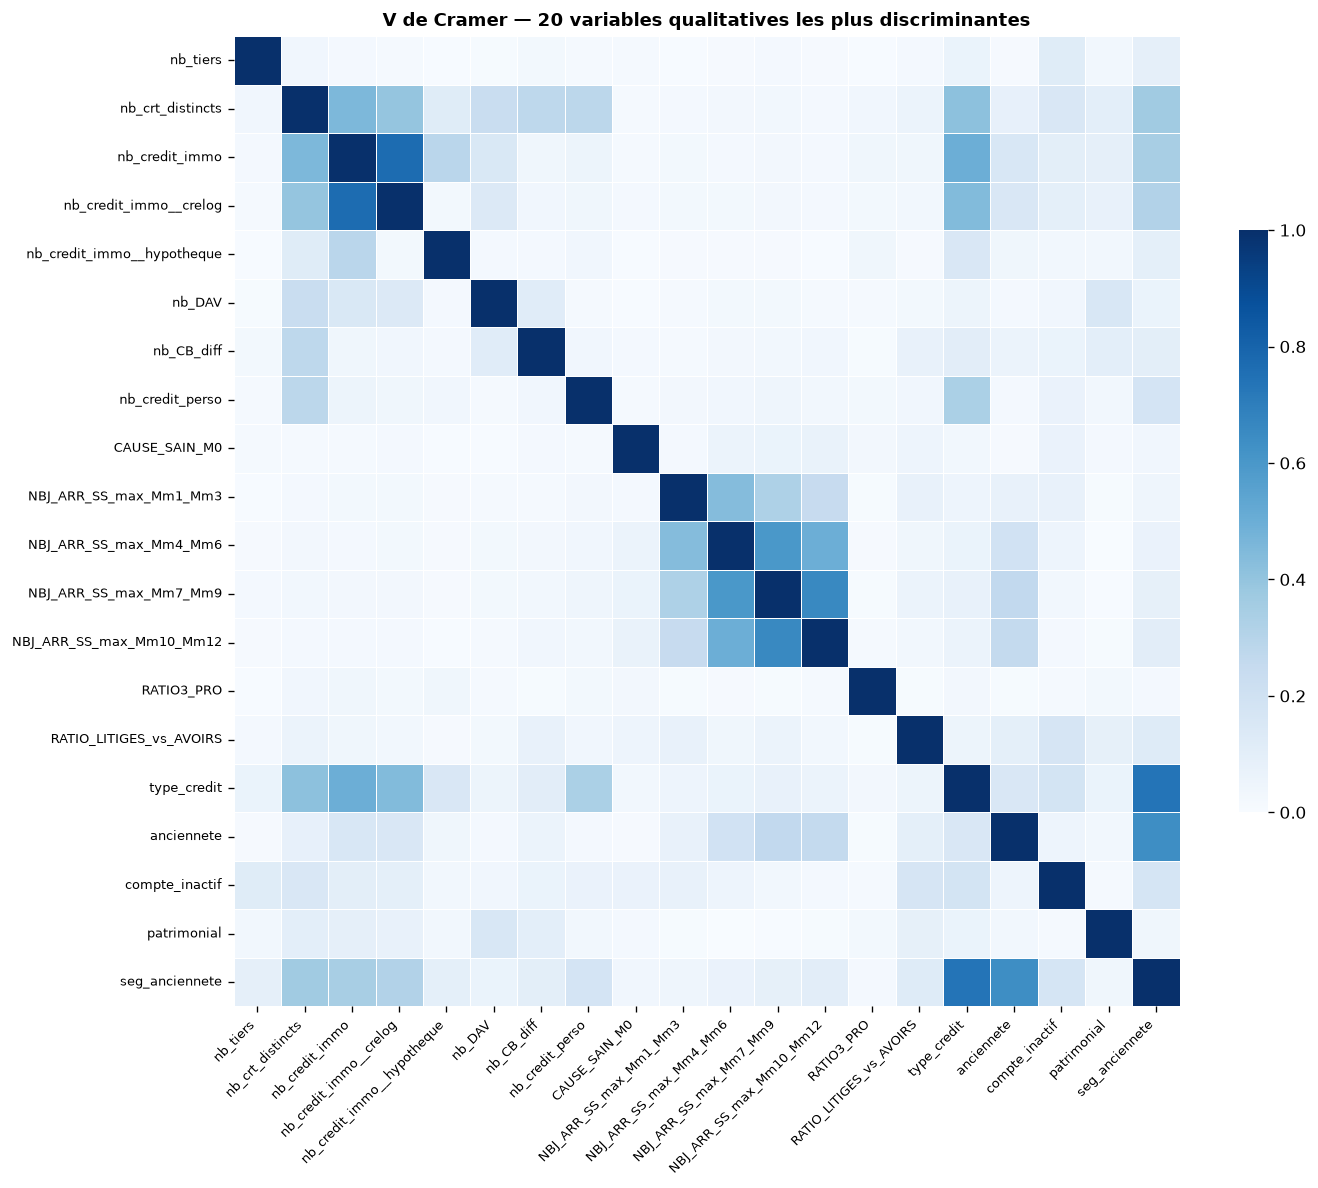

In [10]:
v_cramer = cramers_v_matrix(df, VARS_DISCRETES)

if len(TOP_QUALI) > 1:
    fig = plot_matrice(
        v_cramer.filter(pl.col("variable").is_in(TOP_QUALI)).select("variable", *[c for c in VARS_DISCRETES if c in TOP_QUALI]),
        titre=f"V de Cramer — {len(TOP_QUALI)} variables qualitatives les plus discriminantes",
        vmin=0, cmap="Blues",
    )
    plt.show()

In [11]:
paires_quali = paires_fortes(v_cramer, SEUIL_CRAMER, "cramers_v")

print(f"{paires_quali.height} paires avec V de Cramer >= {SEUIL_CRAMER}")
paires_quali.head(30)

0 paires avec V de Cramer >= 0.8


var1,var2,cramers_v
str,str,f64


## 3.3 Quanti / quali : ANOVA, eta², Kruskal-Wallis

| Outil | Question | Hypothèses |
|-------|----------|------------|
| **ANOVA** (F) | les moyennes diffèrent-elles entre groupes ? | normalité, variances égales |
| **eta²** | quelle part de la variance est expliquée par les groupes ? (0 à 1) | — |
| **Kruskal-Wallis** | les distributions diffèrent-elles ? (test sur les rangs) | aucune hypothèse de loi |

Les montants étant très asymétriques, les hypothèses de l'ANOVA sont rarement tenues : le
Kruskal-Wallis est la référence, l'ANOVA est donnée pour comparaison.

### Liaison avec la cible

La cible joue ici le rôle de la variable qualitative (sain / défaut).

In [12]:
anova = anova_report(df, VARS_QUANTI, TARGET)

desaccord = anova.filter((pl.col("pvalue_anova") < ALPHA) != (pl.col("pvalue_kruskal") < ALPHA)).height
print(f"{anova.filter(pl.col('pvalue_kruskal') < ALPHA).height} variables significatives selon Kruskal-Wallis, "
      f"{anova.filter(pl.col('pvalue_anova') < ALPHA).height} selon l'ANOVA ({desaccord} désaccords)")

anova.head(N_TOP)

46 variables significatives selon Kruskal-Wallis, 40 selon l'ANOVA (8 désaccords)


variable,n,eta2,F,pvalue_anova,H_kruskal,pvalue_kruskal
str,i64,f64,f64,f64,f64,f64
"""ARR_GDT""",47156,0.015007,718.409018,4.4908e-157,722.292193,4.2484e-159
"""CRTAD_AG_NBJDE_BB""",47156,0.010598,505.086572,2.8629e-111,328.981462,1.6019e-73
"""CRTAD_IND_0015""",47156,0.010537,502.13318,1.2377e-110,347.914788,1.2057e-77
"""CRTAD_AG_NBJDE_BA""",47156,0.009949,473.863902,1.5161e-104,290.061036,4.8223e-65
"""CRTAD_AG_NBJDE_BC""",47156,0.006395,303.507042,9.2535e-68,206.792585,6.8811e-47
"""NBJ_ARR_SS_max_Mm1_Mm3""",46986,0.005686,268.661182,3.2666e-60,276.524336,4.2956e-62
"""NBJ_ARR_SS_max_Mm7_Mm9""",46018,0.005646,261.270817,1.3158e-58,259.801387,1.8959e-58
"""NBJ_ARR_SS_max_Mm10_Mm12""",45574,0.005022,230.012993,7.9291e-52,198.653446,4.1085e-45
"""NBJ_ARR_SS_max_Mm13_Mm18""",45207,0.004508,204.686692,2.5029e-46,162.951254,2.5637e-37


### Liaison entre variables explicatives

eta² de chaque variable continue (ligne) selon chaque variable qualitative (colonne) : repère les
redondances entre variables de natures différentes, que les sections 3.1 et 3.2 ne voient pas.

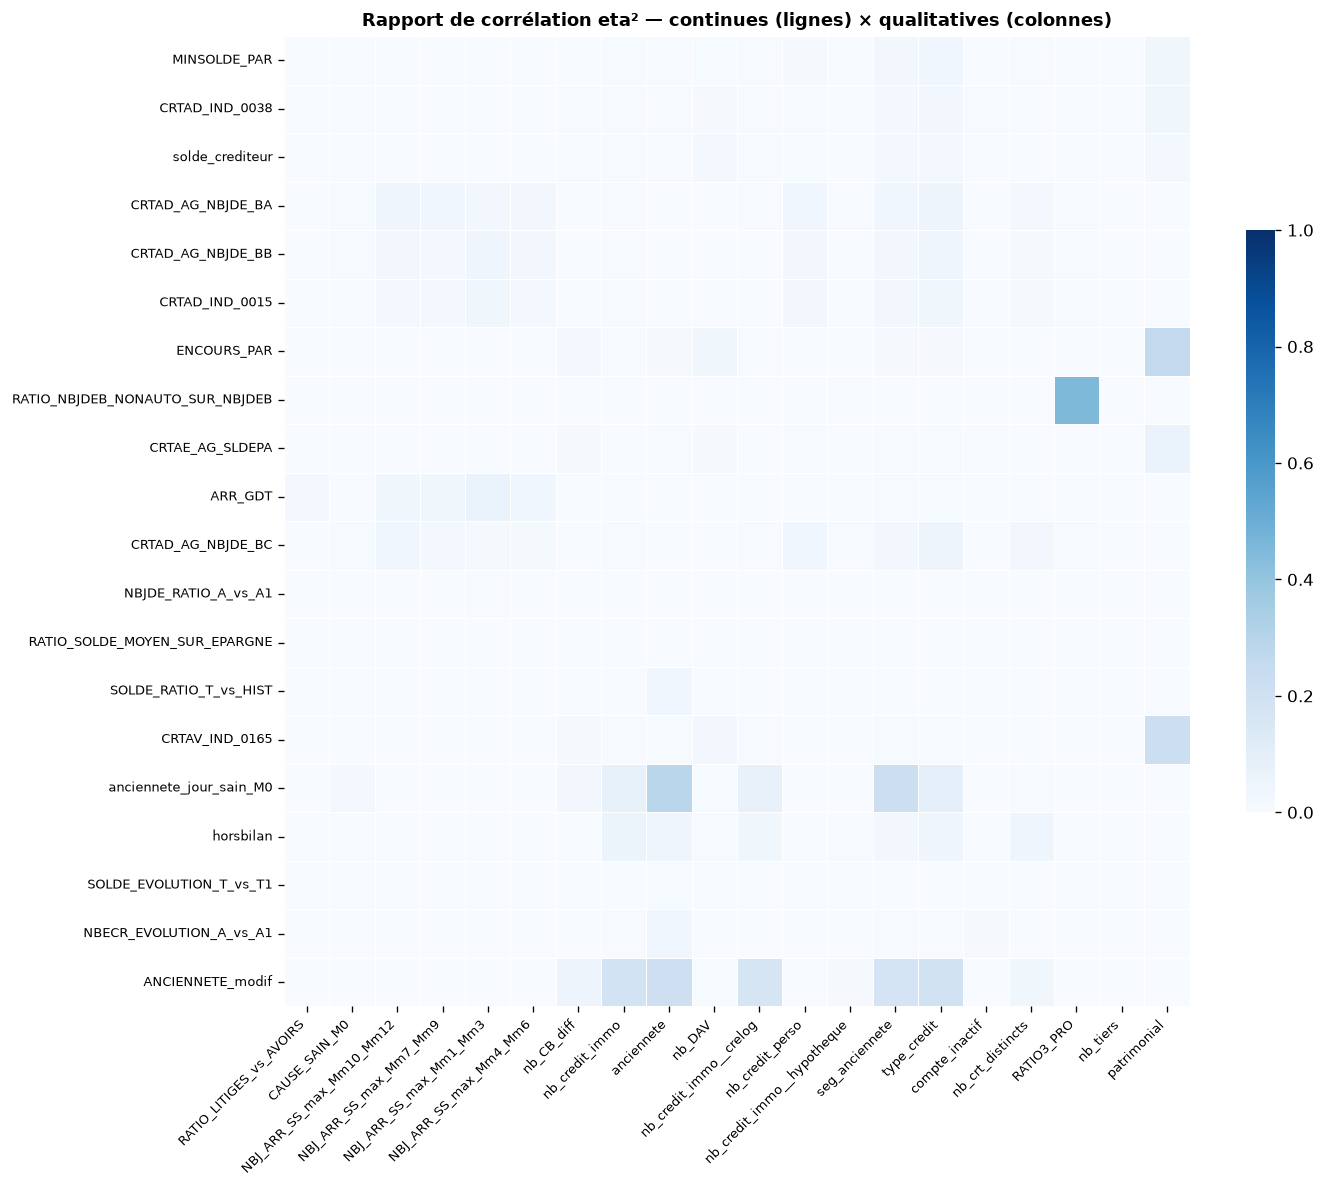

In [13]:
if TOP_QUANTI and TOP_QUALI:
    eta2_croise = eta2_matrix(df, TOP_QUANTI, TOP_QUALI)
    fig = plot_matrice(eta2_croise, titre="Rapport de corrélation eta² — continues (lignes) × qualitatives (colonnes)",
                       vmin=0, cmap="Blues")
    plt.show()

## 3.4 Multicolinéarité : VIF, matrice de corrélation, ACP exploratoire

La corrélation regarde les variables **deux à deux**. La multicolinéarité est plus générale : une
variable peut être presque une combinaison linéaire de *plusieurs* autres sans être fortement
corrélée à aucune d'elles.

- **VIF** = 1 / (1 − R²), où R² vient de la régression de la variable sur toutes les autres.
  Repères usuels : VIF > 5 préoccupant, VIF > 10 sévère.
- **ACP exploratoire** : si peu d'axes concentrent l'essentiel de la variance, les variables se
  regroupent en quelques familles redondantes ; le cercle des corrélations montre lesquelles.

Ces deux outils exigent une matrice sans manquant : les manquants sont remplacés par la médiane
**pour ce diagnostic uniquement** (la base n'est pas modifiée). Ils sont appliqués aux variables
continues les plus discriminantes.

In [14]:
VARS_MULTI = [c for c in TOP_QUANTI if df[c].drop_nulls().n_unique() > 1]

vif = vif_report(completer_mediane(df, VARS_MULTI), VARS_MULTI)

print(f"{vif.filter(pl.col('VIF') > SEUIL_VIF).height} variables avec VIF > {SEUIL_VIF}, "
      f"{vif.filter(pl.col('VIF') > 10).height} avec VIF > 10")
vif

7 variables avec VIF > 5, 2 avec VIF > 10


variable,VIF
str,f64
"""CRTAD_AG_NBJDE_BA""",17.60284
"""CRTAD_AG_NBJDE_BB""",16.057008
"""ENCOURS_PAR""",9.947104
"""CRTAD_IND_0015""",8.849201
"""CRTAD_AG_NBJDE_BC""",7.390887
"""CRTAD_IND_0038""",7.06216
"""CRTAV_IND_0165""",6.526504
"""solde_crediteur""",4.114152
"""MINSOLDE_PAR""",3.425146


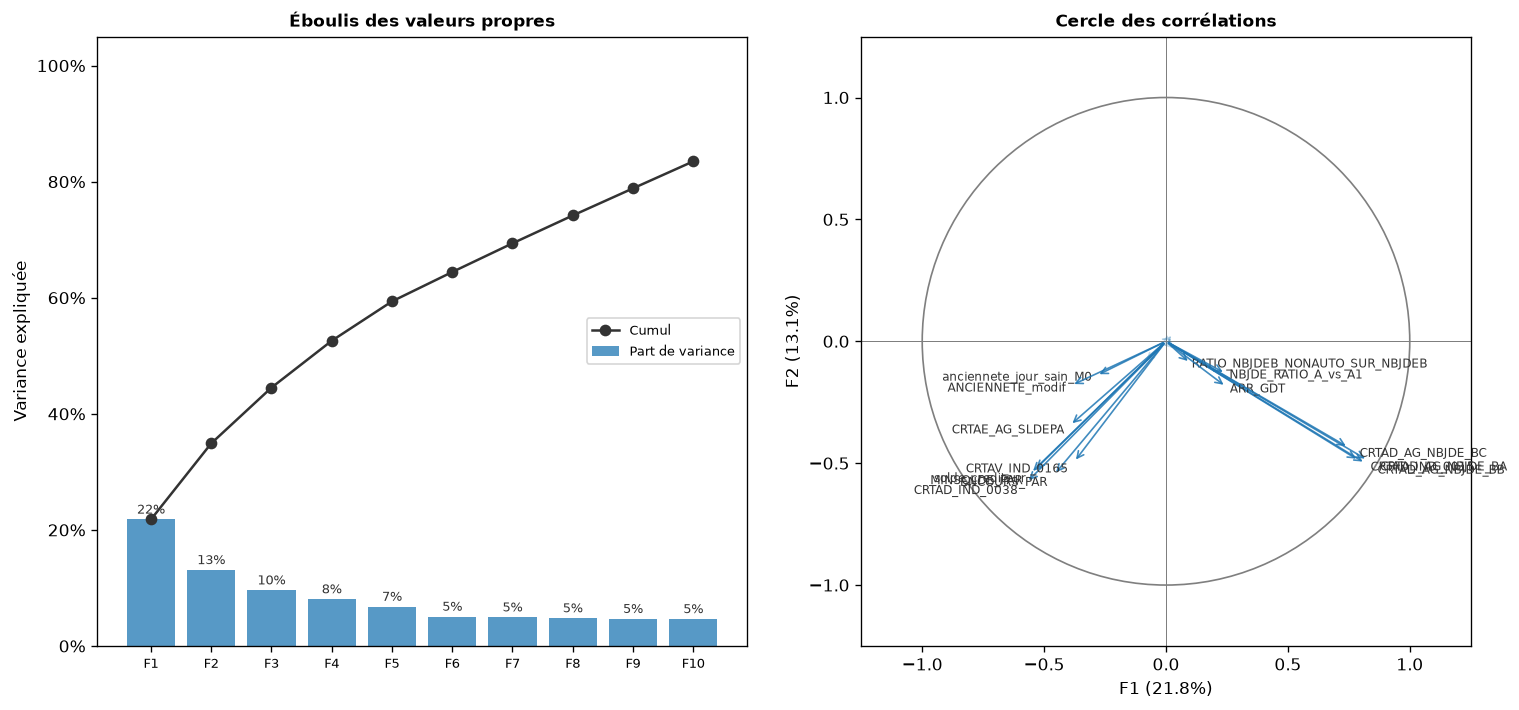

6 axes de valeur propre > 1 (critère de Kaiser) pour 20 variables


axe,valeur_propre,part_variance,part_cumulee
str,f64,f64,f64
"""F1""",4.361338,0.218067,0.218067
"""F2""",2.620172,0.131009,0.349075
"""F3""",1.921597,0.09608,0.445155
"""F4""",1.614594,0.08073,0.525885
"""F5""",1.356686,0.067834,0.593719
"""F6""",1.012317,0.050616,0.644335
"""F7""",0.988889,0.049444,0.69378
"""F8""",0.959021,0.047951,0.741731
"""F9""",0.934912,0.046746,0.788476


In [15]:
variance, correlations = acp_exploratoire(df, VARS_MULTI, n_composantes=5)

fig = plot_acp(variance, correlations, axes=("F1", "F2"))
plt.show()

n_kaiser = variance.filter(pl.col("valeur_propre") > 1).height
print(f"{n_kaiser} axes de valeur propre > 1 (critère de Kaiser) pour {len(VARS_MULTI)} variables")
variance.head(10)

In [16]:
afficher(lecture_acp(variance, correlations, axes=("F1", "F2")))

- **F1** (21,8% de la variance) — pôle positif : `CRTAD_AG_NBJDE_BA`, `CRTAD_AG_NBJDE_BB`, `CRTAD_IND_0015`, `CRTAD_AG_NBJDE_BC` ; pôle négatif : `CRTAD_IND_0038`, `MINSOLDE_PAR`, `solde_crediteur` (|r| ≥ 0,5).
- **F2** (13,1% de la variance) — pôle positif : aucune ; pôle négatif : `CRTAD_IND_0038`, `ENCOURS_PAR`, `MINSOLDE_PAR`, `solde_crediteur`, `CRTAD_AG_NBJDE_BB` (|r| ≥ 0,5).
- Les axes F1 et F2 résument **34,9%** de la variance.

**Lecture** : F1 (21,8 %) oppose les **jours débiteurs** (`CRTAD_AG_NBJDE_BA/BB/BC`, `CRTAD_IND_0015`) aux **soldes
créditeurs** (`CRTAD_IND_0038`, `MINSOLDE_PAR`, `solde_crediteur`) : c'est un axe de **tension de trésorerie**. F2 (13,1 %)
est porté par le **niveau des soldes et des encours** (`ENCOURS_PAR`) : un axe de patrimoine. Les variables proches sur ces
axes sont exactement celles des paires redondantes de la section 3.1. Six axes ont une valeur propre > 1 pour 20 variables :
l'information se répartit en quelques familles (trésorerie, patrimoine, évolution du solde, ancienneté).

L'ACP reste ici un outil de **diagnostic**. Les axes ne sont pas utilisés comme variables du modèle :
ils ne sont pas interprétables variable par variable, ce qui est incompatible avec une grille de score.

## 3.5 Détecter les relations non monotones

Pearson, Spearman et Kendall ne voient que les liaisons monotones. Une variable dont le risque est
élevé aux deux extrémités et faible au centre (relation en U) a une corrélation proche de zéro avec
la cible, alors qu'elle discrimine bien.

On le détecte en découpant chaque variable en classes fines et en regardant le taux de défaut par classe :

- `rho_classes` : Spearman entre le rang de la classe et son taux de défaut (±1 = monotone) ;
- `n_inversions` : nombre de changements de sens du taux de défaut ;
- `non_monotone` : la variable discrimine (IV ≥ 0,02) mais `|rho_classes|` < 0,7.

In [17]:
monotonie = monotonie_report(df, VARS_QUANTI, TARGET, max_modalites=MAX_MODALITES, iv_min=IV_MIN)

non_monotones = monotonie.filter(pl.col("non_monotone"))
print(f"{non_monotones.height} variables discriminantes à relation non monotone")
non_monotones

22 variables discriminantes à relation non monotone


variable,iv,n_classes,rho_classes,n_inversions,tdr_min,tdr_max,non_monotone
str,f64,i64,f64,i64,f64,f64,bool
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.820455,10,0.225614,3,0.000563,0.010977,true
"""RATIO_LITIGES_vs_AVOIRS""",0.693028,14,0.312067,6,0.0,1.0,true
"""SOLDE_RATIO_T_vs_HIST""",0.681972,10,-0.048632,3,0.001289,0.016967,true
"""SOLDE_EVOLUTION_T_vs_T1""",0.523046,10,-0.085631,1,0.001939,0.015938,true
"""NBECR_EVOLUTION_A_vs_A1""",0.511617,10,-0.187879,3,0.001733,0.0131,true
"""SOLDE_EVOLUTION_T_vs_T4""",0.50118,10,-0.054545,5,0.001741,0.015234,true
"""PART_EPARGNE_DANS_AVOIRS""",0.42365,5,0.1,1,0.00108,0.004093,true
"""SOLDE_PENTE_5T""",0.406395,10,-0.624242,2,0.000848,0.010176,true
"""bilan""",0.405144,6,-0.085714,3,0.00269,0.017585,true


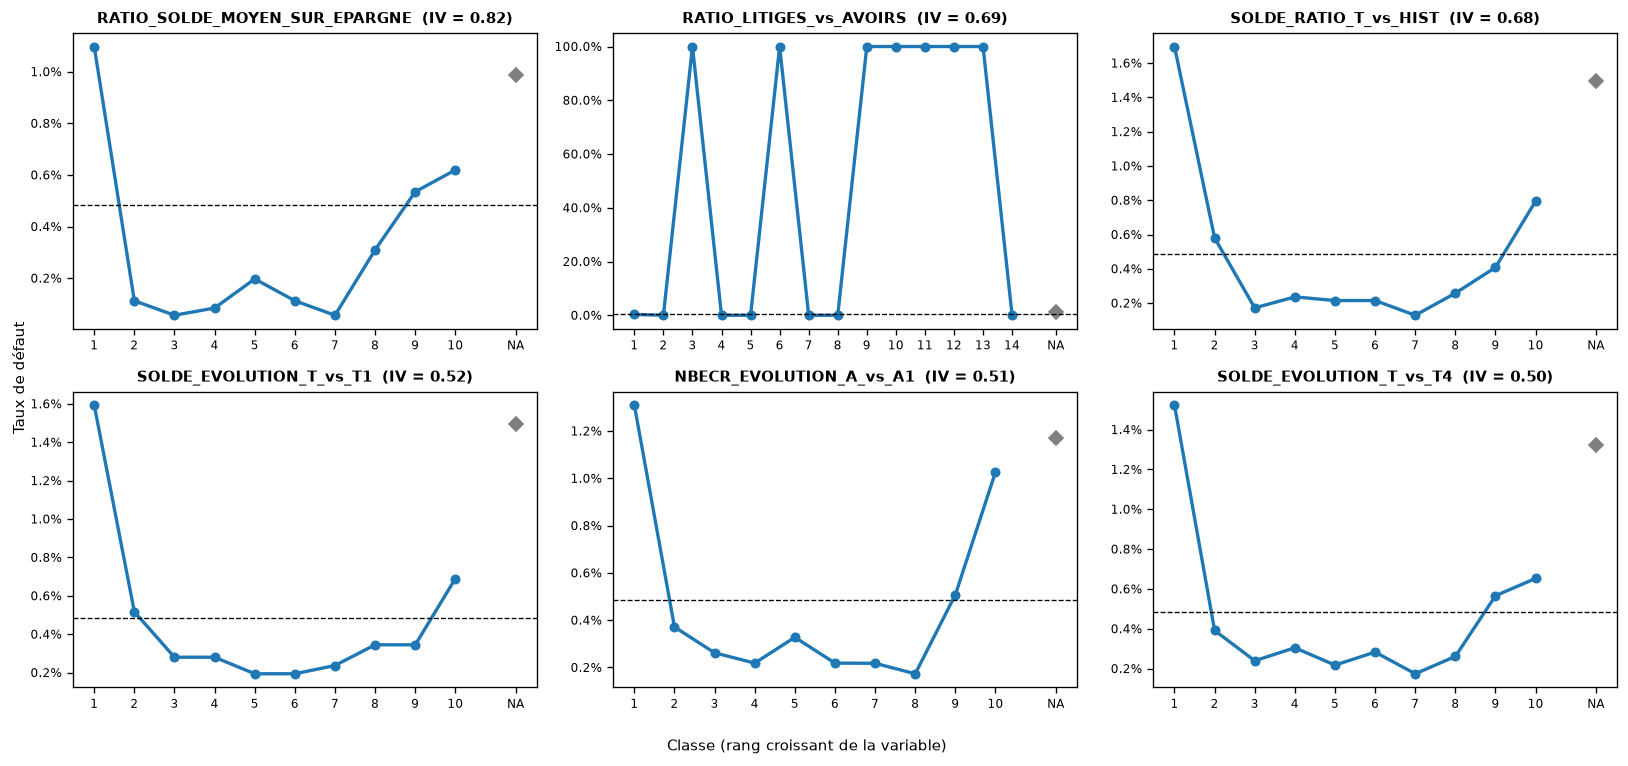

In [18]:
VARS_FORME = non_monotones["variable"].head(6).to_list() or monotonie["variable"].head(6).to_list()

fig = plot_tdr_classes(df, VARS_FORME, TARGET, max_modalites=MAX_MODALITES)
plt.show()

Pour chaque variable non monotone : si la forme a un sens métier, elle sera respectée par le regroupement de
classes (ch. 4.4, `SENS[var] = 0` dans le notebook 1a) ; sinon c'est du bruit d'échantillonnage et les classes
seront fusionnées pour retrouver une relation monotone.

**Constat** : 24 variables sont signalées non monotones. Deux cas :

| Variables | Forme observée | Lecture | Décision au ch. 4 |
|-----------|----------------|---------|-------------------|
| `SOLDE_EVOLUTION_T_vs_T1`, `…_T4`, `SOLDE_RATIO_T_vs_HIST`, `SOLDE_PENTE_*` | risque élevé aux **deux extrémités** (forte baisse comme forte hausse du solde) | une forte variation dans un sens ou dans l'autre signale un compte instable ; la hausse est moins intuitive | monotonie imposée (pas d'exemption) : le découpage garde le côté le plus discriminant |
| `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB`, ratios d'épargne, `bilan`, `engagement` | inversions isolées entre déciles voisins | bruit d'échantillonnage (200 défauts répartis sur 10 classes) | fusion des classes pour retrouver une relation monotone |

Aucune exemption de monotonie n'est accordée (`SENS` vide en 1a) : c'est le choix par défaut du cours (4.4), le plus
stable. **Décision à prendre** : une relation en U sur les évolutions de solde mérite-t-elle une exemption documentée ?

## 3.6 Limites pour la sélection de variables prédictives

Les mesures de ce chapitre ne suffisent pas à choisir les variables du modèle :

1. **Elles sont univariées ou bivariées** : une variable faible seule peut être utile en présence
   des autres, et inversement.
2. **La significativité n'est pas la force** : sur un grand échantillon, presque tous les tests
   rejettent l'indépendance. Seules les mesures d'intensité (V de Cramer, eta², IV) se comparent.
3. **Les corrélations manquent le non-monotone** (3.5).
4. **La redondance ne dit pas laquelle garder** : entre deux variables liées, le choix se fait sur
   le pouvoir discriminant, la stabilité et le sens métier.

L'illustration ci-dessous compare le rang d'une variable selon la corrélation de Spearman avec la
cible et selon son IV : les plus forts écarts de rang sont les variables qu'un tri par corrélation
aurait sous-estimées.

In [19]:
rangs = (
    iv.select("variable", "iv", "pouvoir")
    .join(liaison.select("variable", "spearman"), on="variable")
    .join(monotonie.select("variable", "rho_classes", "non_monotone"), on="variable")
    .with_columns(
        rang_iv=pl.col("iv").rank("ordinal", descending=True),
        rang_spearman=pl.col("spearman").abs().rank("ordinal", descending=True),
    )
    .with_columns(ecart_rang=pl.col("rang_spearman").cast(pl.Int64) - pl.col("rang_iv").cast(pl.Int64))
    .sort("ecart_rang", descending=True, nulls_last=True)
)
rangs.head(10)

variable,iv,pouvoir,spearman,rho_classes,non_monotone,rang_iv,rang_spearman,ecart_rang
str,f64,str,f64,f64,bool,u32,u32,i64
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…",1.093659,"""suspect""",-0.000706,null,null,8,56,48
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.820455,"""suspect""",-0.002057,0.225614,true,13,54,41
"""NBECR_EVOLUTION_A_vs_A1""",0.511617,"""suspect""",-0.005671,-0.187879,true,20,51,31
"""PART_EPARGNE_DANS_AVOIRS""",0.42365,"""fort""",0.015129,0.1,true,24,41,17
"""RATIO_MOUV_AFF_SUR_EPARGNE""",0.322325,"""fort""",0.007135,null,null,34,49,15
"""SOLDE_RATIO_T_vs_HIST""",0.681972,"""suspect""",-0.023979,-0.048632,true,15,29,14
"""engagement""",0.25283,"""moyen""",-0.003263,-0.033333,true,39,53,14
"""CRTAV_IND_0165""",0.665568,"""suspect""",-0.031207,-0.8,false,16,27,11
"""SOLDE_EVOLUTION_T_vs_T1""",0.523046,"""suspect""",-0.023767,-0.085631,true,19,30,11


### Statut provisoire de chaque variable

Les constats du chapitre sont rassemblés dans une fiche par variable. Le statut est **provisoire** :
il prépare la discrétisation (ch. 4), la sélection finale se fera dans le modèle (ch. 5).

Règles, dans l'ordre (paramètres identiques à la présélection du notebook `0c`) :

- quasi constante (une valeur couvre au moins 99 % des dossiers) → écartée ;
- au moins 95 % de manquants → écartée. Pour les qualitatives, le manquant étant devenu la modalité
  `"missing"` en `0c`, c'est la part de cette modalité qui est mesurée ;
- IV < 0,02 → écartée (non discriminante) ;
- redondante avec une variable de meilleur IV (paires des sections 3.1 et 3.2) → écartée ;
- IV > 0,5 → conservée avec une alerte (soupçon de fuite d'information).

**Seuil de redondance : 0,9 en `0c`, 0,8 ici.** Les deux étapes forment un entonnoir volontaire : `0c`
ne retire que les quasi-doublons (|Spearman| ou V ≥ 0,9), pour alléger la base sans perdre
d'information ; ce notebook applique le seuil usuel de 0,8, après examen des matrices de corrélation.

Le VIF (3.4) figure dans la fiche à titre d'information : il n'entraîne pas d'exclusion à ce stade,
la multicolinéarité étant retestée dans le modèle multivarié (ch. 5, tests par variable).

In [20]:
# Taux de manquants : null pour les quantitatives, modalité « missing » pour les qualitatives (cf. 0c)
taux_missing = df.select(
    *[pl.col(c).null_count() / pl.len() for c in VARS_QUANTI],
    *[(pl.col(c) == "missing").mean() for c in VARS_QUALI],
).cast(pl.Float64).transpose(include_header=True, header_name="variable", column_names=["taux_missing"])

fiche = (
    taux_missing
    .join(constant_report(df, VARS).select("variable", "part_top", "quasi_constante"), on="variable")
    .join(iv.select("variable", "iv", "pouvoir"), on="variable")
    .join(liaison.select("variable", "spearman"), on="variable", how="left")
    .join(monotonie.select("variable", "non_monotone"), on="variable", how="left")
    .join(vif.select("variable", "VIF"), on="variable", how="left")
)
paires = pl.concat([paires_quanti.select("var1", "var2"), paires_quali.select("var1", "var2")])

synthese = preselection_variables(
    fiche, paires, iv_min=IV_MIN, missing_max=MISSING_MAX, iv_rare=IV_RARE,
).sort("iv", descending=True)

synthese.group_by("statut").len().sort("len", descending=True)

statut,len
str,u32
"""candidate""",32
"""candidate : IV > 0,5, vérifier…",19
"""écartée : redondante""",11


In [21]:
synthese.filter(pl.col("statut").str.starts_with("candidate"))

variable,taux_missing,part_top,quasi_constante,iv,pouvoir,spearman,non_monotone,VIF,redondante_avec,statut
str,f64,f64,bool,f64,str,f64,bool,f64,str,str
"""MINSOLDE_PAR""",0.0,0.022881,false,1.884791,"""suspect""",-0.081082,false,3.425146,null,"""candidate : IV > 0,5, vérifier…"
"""solde_crediteur""",0.0,0.056366,false,1.56405,"""suspect""",-0.076699,false,4.114152,null,"""candidate : IV > 0,5, vérifier…"
"""CRTAD_AG_NBJDE_BA""",0.0,0.450377,false,1.481339,"""suspect""",0.07843,false,17.60284,null,"""candidate : IV > 0,5, vérifier…"
"""CRTAD_IND_0015""",0.0,0.702159,false,1.262532,"""suspect""",0.085896,false,8.849201,null,"""candidate : IV > 0,5, vérifier…"
"""ENCOURS_PAR""",0.0,0.217194,false,1.165671,"""suspect""",-0.061239,false,9.947104,null,"""candidate : IV > 0,5, vérifier…"
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…",0.700059,0.700059,false,1.093659,"""suspect""",-0.000706,null,1.011961,null,"""candidate : IV > 0,5, vérifier…"
"""ARR_GDT""",0.0,0.967236,false,0.886608,"""suspect""",0.123764,null,1.061009,null,"""candidate : IV > 0,5, vérifier…"
"""NBJDE_RATIO_A_vs_A1""",0.571677,0.571677,false,0.865903,"""suspect""",0.049096,false,1.276305,null,"""candidate : IV > 0,5, vérifier…"
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.246628,0.246628,false,0.820455,"""suspect""",-0.002057,true,1.045794,null,"""candidate : IV > 0,5, vérifier…"


### Constat

In [22]:
afficher(constat_preselection(synthese))

| Statut | Variables |
|---|---|
| candidate | 32 |
| candidate : IV > 0,5, vérifier la fuite | 19 |
| écartée : redondante | 11 |

**Redondances** (11) : variable écartée → variable qui la représente.

| Écartée | IV | Représentée par |
|---|---|---|
| `CRTAD_IND_0038` | 1,615 | `MINSOLDE_PAR` |
| `CRTAD_AG_NBJDE_BB` | 1,378 | `CRTAD_AG_NBJDE_BA` |
| `CRTAE_AG_SLDEPA` | 1,023 | `ENCOURS_PAR` |
| `CRTAD_AG_NBJDE_BC` | 0,873 | `CRTAD_AG_NBJDE_BA` |
| `PART_EPARGNE_DANS_AVOIRS` | 0,424 | `CRTAV_IND_0165` |
| `SOLDE_PENTE_4T` | 0,395 | `SOLDE_PENTE_5T` |
| `engagement_DAV` | 0,340 | `horsbilan` |
| `engagement` | 0,253 | `bilan` |
| `CRTAD_AG_NBECR_B` | 0,166 | `CRTAD_IND_0042` |
| `NBECR_PAR` | 0,139 | `NBECR_EVOLUTION_A_vs_A1` |

… et 1 autres (voir le tableau ci-dessus).

- Alertes IV > 0,5 (soupçon de fuite) : `MINSOLDE_PAR`, `solde_crediteur`, `CRTAD_AG_NBJDE_BA`, `CRTAD_IND_0015`, `ENCOURS_PAR`, `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB`, `ARR_GDT`, `NBJDE_RATIO_A_vs_A1` … (+11 autres).

- **Redondances** (11, au seuil de 0,8) : soldes (`CRTAD_IND_0038` → `MINSOLDE_PAR`), jours débiteurs (`CRTAD_AG_NBJDE_BB`, `_BC`
  → `CRTAD_AG_NBJDE_BA`), encours (`CRTAE_AG_SLDEPA` → `ENCOURS_PAR`), pentes de solde (`SOLDE_PENTE_4T` → `_5T`), épargne
  (`PART_EPARGNE_DANS_AVOIRS` → `CRTAV_IND_0165`), engagements (`engagement` → `bilan`, `engagement_DAV` → `horsbilan`).
  Dans chaque groupe, la représentante est la plus discriminante et reste lisible métier.
- **Alertes IV > 0,5** (20) : variables de fonctionnement du compte, connues à la date d'observation ; pas de fuite
  identifiée (les défauts en cours sont exclus en amont).

### Vue d'ensemble : pouvoir discriminant et redondances

Une barre par variable, classées par IV décroissante. Au-dessus de chaque barre figurent les variables
auxquelles elle est corrélée (paires des sections 3.1 et 3.2). Les pointillés sont les seuils de
Siddiqi (0,02 – 0,1 – 0,3 – 0,5).

Lecture : dans un groupe de variables corrélées entre elles, on ne garde en principe que la barre la
plus haute.

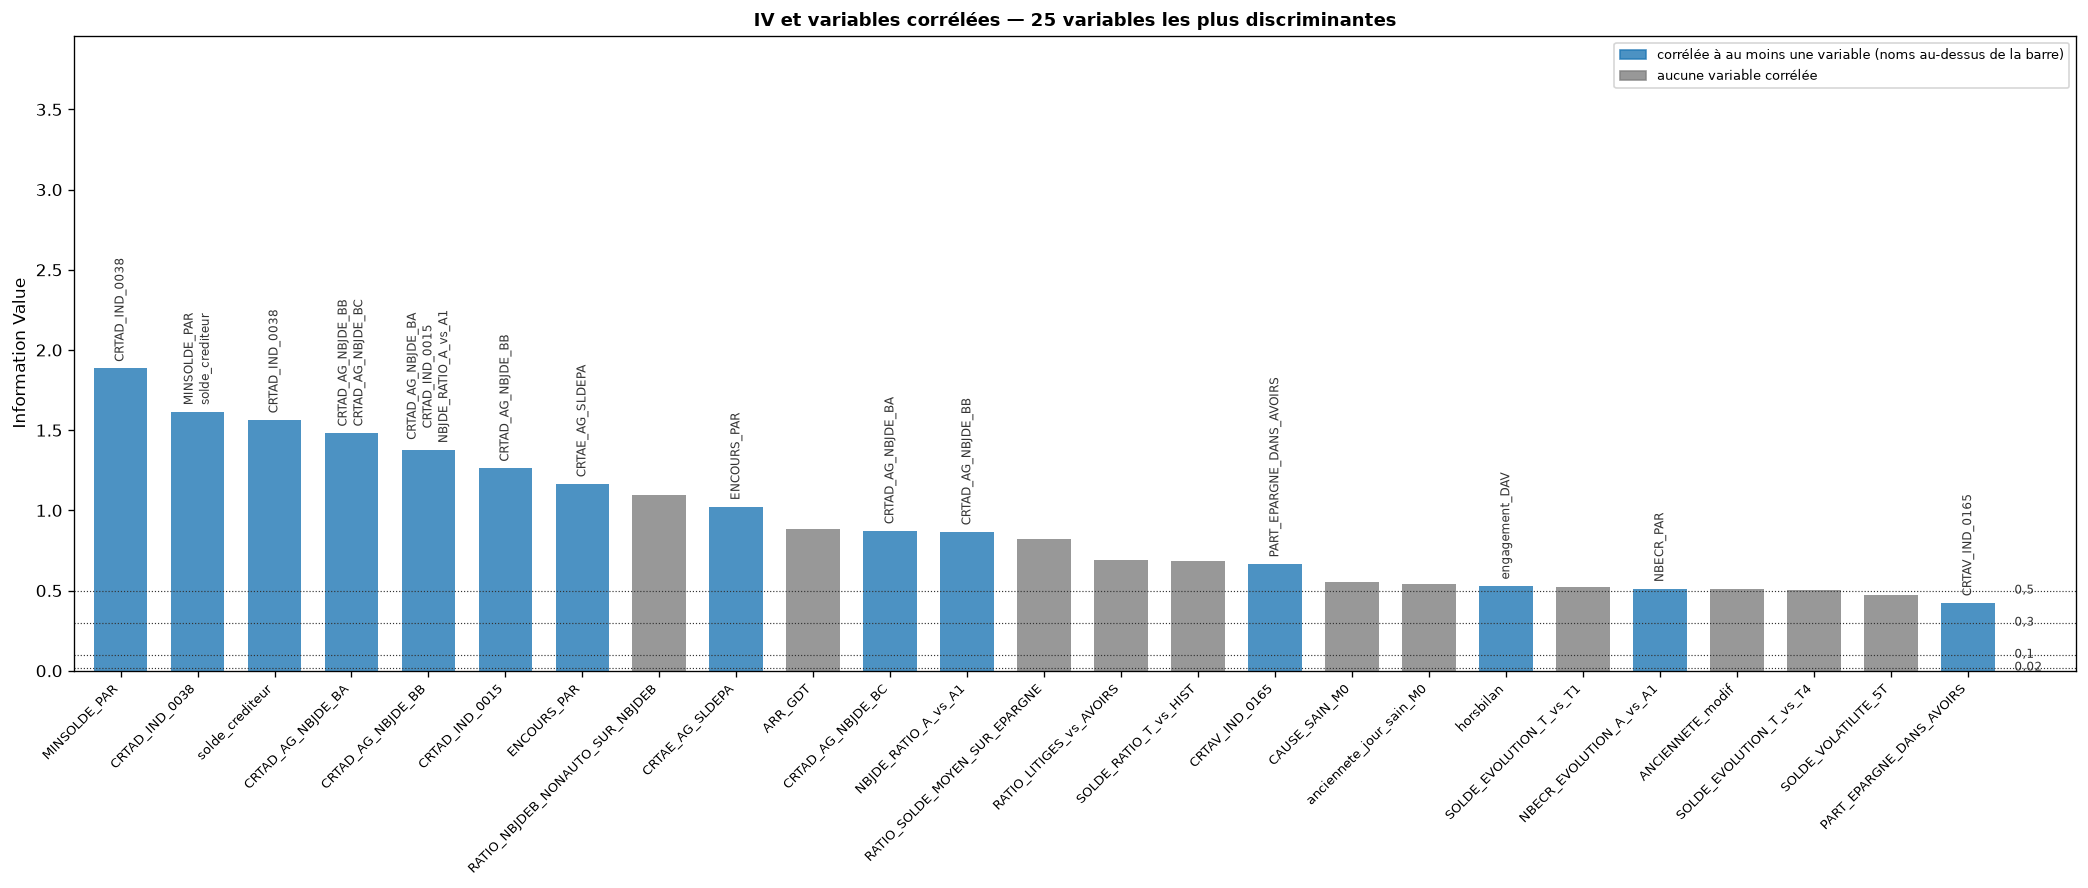

In [23]:
fig = plot_iv_correlees(iv, paires, top_n=25, max_liees=4)
plt.show()

In [24]:
exporter_excel({
    "synthese": synthese,
    "iv": iv,
    "liaison_quanti_cible": liaison,
    "chi2_cible": chi2_cible,
    "anova_kruskal": anova,
    "paires_spearman": paires_quanti,
    "paires_cramer": paires_quali,
    "vif": vif,
    "acp_variance": variance,
    "monotonie": monotonie,
}, EXPORT)
print(f"Tables exportées : {EXPORT}")

# Liste des variables candidates, lue par le notebook de discrétisation (ch. 4)
import json
VARS_CANDIDATES = synthese.filter(pl.col("statut").str.starts_with("candidate"))["variable"].to_list()
CANDIDATES.parent.mkdir(parents=True, exist_ok=True)
CANDIDATES.write_text(json.dumps(VARS_CANDIDATES, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"{len(VARS_CANDIDATES)} variables candidates enregistrées : {CANDIDATES}")

Tables exportées : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\exploration\exploration_joint.xlsx
51 variables candidates enregistrées : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\exploration\variables_candidates_joint.json


## Synthèse des décisions

Le tableau ci-dessous est rempli à partir des résultats du notebook.

> **Prochaine étape** : discrétisation et regroupement de modalités (ch. 4) sur les variables candidates
> (`outputs/exploration/variables_candidates_joint.json`).

In [25]:
afficher(synthese_exploration(
    paires_quanti, paires_quali, vif, non_monotones, synthese,
    eta2_croise=globals().get("eta2_croise"),
    seuil_corr=SEUIL_CORR, seuil_cramer=SEUIL_CRAMER, seuil_vif=SEUIL_VIF,
))

| § | Constat | Décision |
|---|---|---|
| 3.1 Quanti / quanti | 15 paires avec \|Spearman\| ≥ 0,8 | une seule variable conservée par paire (meilleur IV) |
| 3.2 Quali / quali | 0 paires avec V de Cramer ≥ 0,8 | une seule variable conservée par paire (meilleur IV) |
| 3.3 Quanti / quali | 0 couples avec eta² ≥ 0,5 | diagnostic : redondances croisées signalées, sans exclusion automatique |
| 3.4 Multicolinéarité | 7 variables avec VIF > 5, 2 avec VIF > 10 | VIF reporté dans la fiche ; traitement au ch. 5 |
| 3.5 Non monotones | 22 variables discriminantes non monotones : `RATIO_SOLDE_MOYEN_SUR_EPARGNE`, `RATIO_LITIGES_vs_AVOIRS`, `SOLDE_RATIO_T_vs_HIST`, `SOLDE_EVOLUTION_T_vs_T1`, `NBECR_EVOLUTION_A_vs_A1` … (+17 autres) | forme à confirmer ou corriger au regroupement de classes (ch. 4.4) |
| 3.6 Présélection | 51 candidates ; 11 écartées pour redondance, 0 pour un autre motif | variables candidates transmises à la discrétisation |